<a href="https://www.pieriandata.com"><img src="data/Logo.jpg"></a>
*Copyright by Pierian Data Inc.*

# Corner Detection

### The Image Data

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

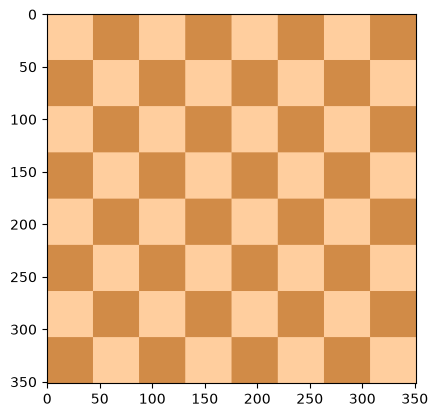

In [2]:
flat_chess = cv2.imread('data/flat_chessboard.png')
flat_chess = cv2.cvtColor(flat_chess, cv2.COLOR_BGR2RGB)
plt.imshow(flat_chess)

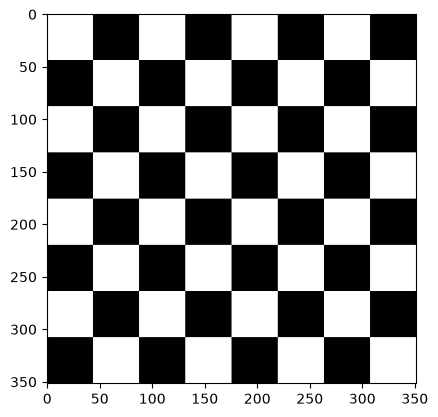

In [15]:
gray_flat_chess = cv2.cvtColor(flat_chess, cv2.COLOR_BGR2GRAY)
plt.imshow(gray_flat_chess, 'gray')

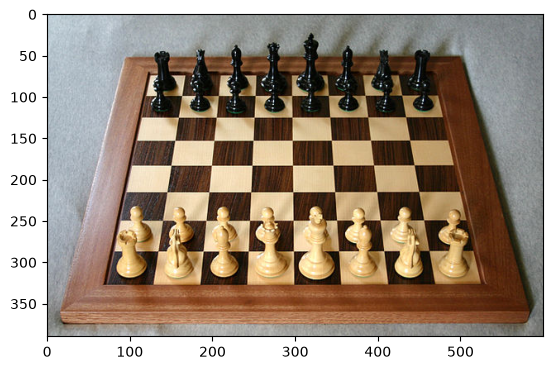

In [8]:
real_chess = cv2.imread('data/real_chessboard.jpg')
real_chess = cv2.cvtColor(real_chess, cv2.COLOR_BGR2RGB)
plt.imshow(real_chess)

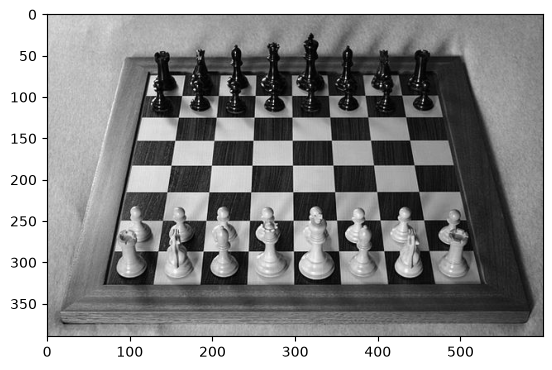

In [9]:
gray_real_chess = cv2.cvtColor(real_chess,cv2.COLOR_BGR2GRAY)
plt.imshow(gray_real_chess,cmap='gray')

# Harris Corner Detection

**cornerHarris Function**

*  `src` $\to$ Input single-channel 8-bit or floating-point image.
*  `dst` $\to$ Image to store the Harris detector responses. It has the type CV_32FC1 and the same size as src .
*  `blockSize` $\to$ Neighborhood size (see the details on #cornerEigenValsAndVecs ).
*  `ksize` $\to$ Aperture parameter for the Sobel operator.
*  `k` $\to$ Harris detector free parameter. See the formula in DocString
*  `borderType` $\to$ Pixel extrapolation method. See #BorderTypes.

**Result**  
- Large positive response: likely corner.
- Negative response: often an edge.
- Response near zero: often a flat region.

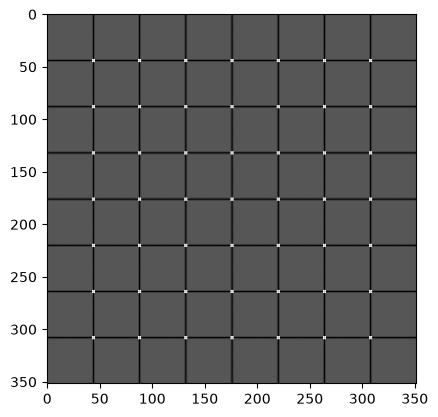

In [22]:
# Convert gray scale image to float values
gray_flat_chess = np.float32(gray_flat_chess)
dst = cv2.cornerHarris(src=gray_flat_chess, blockSize=2, ksize=3, k=0.04)
plt.imshow(dst, 'gray')

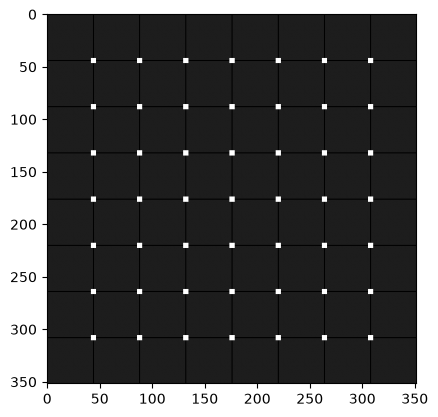

In [20]:
# Result is dilated for marking the corners, not important to actual corner detection
# this is just so we can plot out the points on the image shown
dst = cv2.dilate(src=dst, kernel=None)
plt.imshow(dst, 'gray')

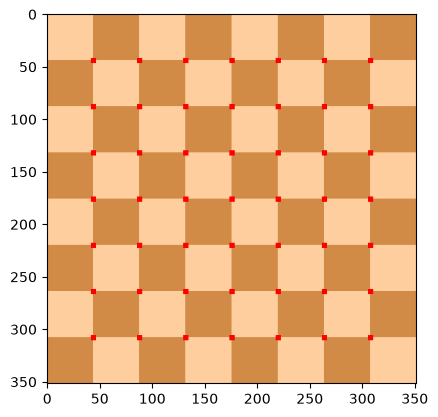

In [23]:
# Threshold for an optimal value, it may vary depending on the image.
flat_chess[dst>0.01*dst.max()] = [255,0,0]
plt.imshow(flat_chess)

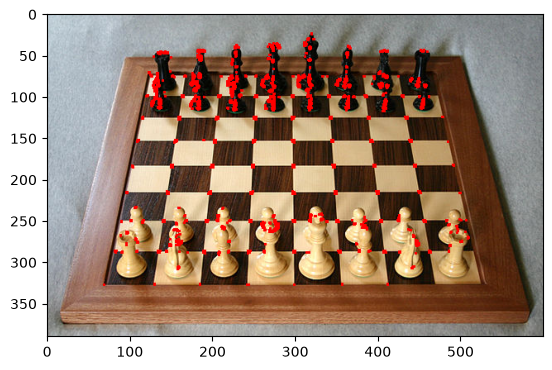

In [25]:
# Convert Gray Scale Image to Float Values
gray = np.float32(gray_real_chess)

# Corner Harris Detection
dst = cv2.cornerHarris(src=gray,blockSize=2,ksize=3,k=0.04)

# result is dilated for marking the corners, not important to actual corner detection
# this is just so we can plot out the points on the image shown
dst = cv2.dilate(dst,None)

# Threshold for an optimal value, it may vary depending on the image.
real_chess[dst>0.01*dst.max()]=[255,0,0]

plt.imshow(real_chess)

-----

## Shi-Tomasi Corner Detector & Good Features to Track Paper

[Link to Paper from Video](http://www.ai.mit.edu/courses/6.891/handouts/shi94good.pdf)

goodFeatureToTrack Function Parameters

* `image` $\to$ Input 8-bit or floating-point 32-bit, single-channel image.
* `corners` $\to$ Output vector of detected corners.
* `maxCorners` $\to$ Maximum number of corners to return. If there are more corners than are found,the strongest of them is returned. `maxCorners <= 0` implies that no limit on the maximum is set and all detected corners are returned.
* `qualityLevel` $\to$ Parameter characterizing the minimal accepted quality of image corners. The parameter value is multiplied by the best corner quality measure, which is the minimal eigenvalue (see #cornerMinEigenVal ) or the Harris function response (see #cornerHarris ). The corners with the quality measure less than the product are rejected. For example, if the best corner has the quality measure = 1500, and the qualityLevel=0.01 , then all the corners with the quality measure less than 15 are rejected.

In [26]:
# Need to reset the images since we drew on them
flat_chess = cv2.imread('data/flat_chessboard.png')
flat_chess = cv2.cvtColor(flat_chess,cv2.COLOR_BGR2RGB)
gray_flat_chess = cv2.cvtColor(flat_chess,cv2.COLOR_BGR2GRAY)

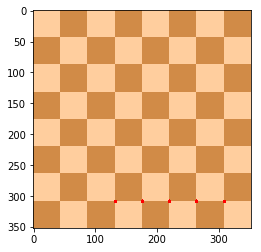

In [10]:
corners = cv2.goodFeaturesToTrack(gray_flat_chess,5,0.01,10) 
corners = np.int0(corners)

for i in corners:
    x,y = i.ravel()
    cv2.circle(flat_chess,(x,y),3,255,-1)

plt.imshow(flat_chess)

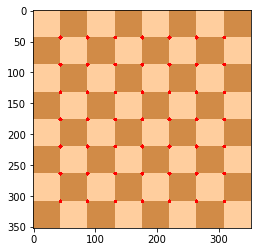

In [11]:
corners = cv2.goodFeaturesToTrack(gray_flat_chess,64,0.01,10)
corners = np.int0(corners)

for i in corners:
    x,y = i.ravel()
    cv2.circle(flat_chess,(x,y),3,255,-1)

plt.imshow(flat_chess)

-----

In [12]:
real_chess = cv2.imread('../DATA/real_chessboard.jpg')
real_chess = cv2.cvtColor(real_chess,cv2.COLOR_BGR2RGB)
gray_real_chess = cv2.cvtColor(real_chess,cv2.COLOR_BGR2GRAY)

In [ ]:
# Test 'ravel()'
a = np.array([[[1,2],[3,4]]])
a.ravel()

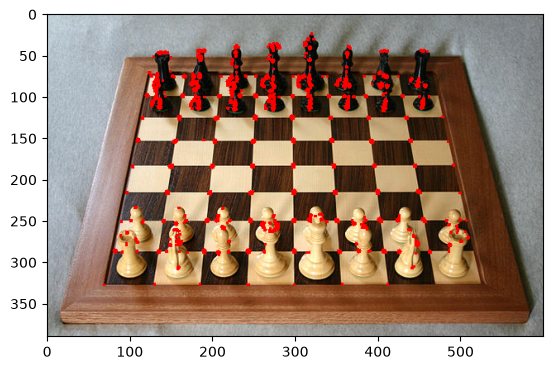

In [37]:
corners = cv2.goodFeaturesToTrack(image=gray_real_chess, maxCorners=5, qualityLevel=0.01, minDistance=10)
corners = corners.astype('int')

for i in corners:
    x,y = i.ravel()
    cv2.circle(img=real_chess, center=(x,y), radius=3, color=255, thickness=-1)

plt.imshow(real_chess)

-----